# Прогнозування доходу українських підприємств

Єдиний виконуваний ноутбук: завантаження готової панелі, EDA, часовий backtesting, моделі N1–N3 і M1–M3, сегменти та висновки.

# 0. Дані та налаштування

Ноутбук не розбирає сирі XML. Він читає одну підготовлену `panel_v1.parquet`, у якій уже об’єднано базові річні зрізи 2021–2024 років із пізніми поданнями, виконано дедуплікацію та додано прапорці аномалій. Цілі обмежені 2024 роком; 2025 рік не використовується.

In [1]:
import sys
!{sys.executable} -m pip -q install -r requirements.txt
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import statsmodels.api as sm

ROOT = Path('/content') if Path('/content').exists() else Path('.')
OUT = ROOT / 'out'
OUT.mkdir(parents=True, exist_ok=True)
HF_REPO = 'Shnnapka/fin-zvit-ua'
PANEL_NAME = 'panel_v1.parquet'

local_panel = OUT / PANEL_NAME
if not local_panel.exists():
    from huggingface_hub import hf_hub_download
    source = hf_hub_download(HF_REPO, f'panel/{PANEL_NAME}', repo_type='dataset', token=False)
    panel = pl.read_parquet(source)
else:
    panel = pl.read_parquet(local_panel)

required = {'edrpou', 't', 'target_year', 'z_t', 'z_lag', 'z_next', 'dz_next',
            'flag_units_x1000', 'flag_balance_mismatch', 'flag_extreme_growth',
            'flag_zero_revenue', 'has_anomaly'}
assert not required.difference(panel.columns), 'panel_v1.parquet has an outdated schema'
assert panel['target_year'].max() == 2024 and panel['target_year'].min() == 2022
f1_lag_missing = panel.filter(pl.col('target_year') == 2022)['z_lag'].is_null().mean()
assert f1_lag_missing < 0.20, 'Outdated panel: F1 still has no 2020 lag; publish cumulative panel_v1'

pl.Config.set_tbl_rows(30)
pl.Config.set_float_precision(4)
print(f'panel: {panel.height:,} rows; companies: {panel["edrpou"].n_unique():,}')
print(panel.group_by('target_year').agg(
    pl.len().alias('rows'),
    pl.col('z_lag').is_null().mean().alias('share_lag_missing'),
).sort('target_year'))


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: /Users/khrystynakorets/Desktop/ua-revenue-forecast/.venv/bin/python -m pip install --upgrade pip


panel: 602,042 rows; companies: 267,961
shape: (3, 3)
┌─────────────┬────────┬───────────────────┐
│ target_year ┆ rows   ┆ share_lag_missing │
│ ---         ┆ ---    ┆ ---               │
│ i64         ┆ u32    ┆ f64               │
╞═════════════╪════════╪═══════════════════╡
│ 2022        ┆ 155690 ┆ 0.0805            │
│ 2023        ┆ 219622 ┆ 0.0557            │
│ 2024        ┆ 226730 ┆ 0.0832            │
└─────────────┴────────┴───────────────────┘


**Висновок.** Панель містить 602 042 рядки для 267 961 підприємства. Частка пропущеного лага становить 8,05% для цілі 2022 року, 5,57% для 2023 та 8,32% для 2024. Отже, F1 тепер має фактичний лаг 2020 року для 91,95% рядків, а перевірка версії зупиняє виконання на старому parquet із повністю порожнім лагом.

# 1. EDA та прапорці

target_year,micro,small,full
i64,u32,u32,u32
2022,44409,99853,11428
2023,65840,140660,13122
2024,71642,142422,12666


target_year,median_y_t,median_z_t,median_dz_next,share_z_next_zero
i64,f64,f64,f64,f64
2022,3769.5500,8.2350,-0.4667,0.0593
2023,1649.6256,7.4089,0.0409,0.0721
2024,1898.9977,7.5496,0.0374,0.0578


flag_units_x1000,flag_balance_mismatch,flag_extreme_growth,flag_zero_revenue,has_anomaly
f64,f64,f64,f64,f64
0.0004,0.0001,0.0584,0.0000,0.0589


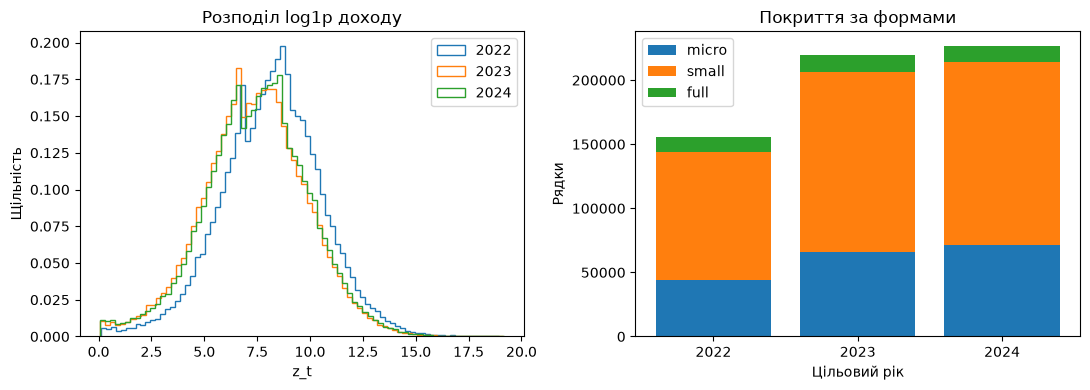

In [2]:
FLAG_COLUMNS = ['flag_units_x1000', 'flag_balance_mismatch',
                'flag_extreme_growth', 'flag_zero_revenue']

coverage = (panel.group_by('target_year', 'form').len()
            .pivot(on='form', index='target_year', values='len').sort('target_year'))
revenue_summary = panel.group_by('target_year').agg(
    pl.col('y_t').median().alias('median_y_t'),
    pl.col('z_t').median().alias('median_z_t'),
    pl.col('dz_next').median().alias('median_dz_next'),
    (pl.col('z_next') == 0).mean().alias('share_z_next_zero'),
).sort('target_year')
flag_summary = panel.select(
    *[pl.col(c).mean().alias(c) for c in FLAG_COLUMNS],
    pl.col('has_anomaly').mean().alias('has_anomaly'),
)
display(coverage)
display(revenue_summary)
display(flag_summary)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for year in panel['target_year'].unique().sort().to_list():
    values = panel.filter(pl.col('target_year') == year)['z_t'].to_numpy()
    axes[0].hist(values, bins=80, density=True, histtype='step', label=str(year))
axes[0].set(title='Розподіл log1p доходу', xlabel='z_t', ylabel='Щільність')
axes[0].legend()
years = coverage['target_year'].to_numpy()
bottom = np.zeros(len(years))
for form in [c for c in coverage.columns if c != 'target_year']:
    values = coverage[form].fill_null(0).to_numpy()
    axes[1].bar(years.astype(str), values, bottom=bottom, label=form)
    bottom += values
axes[1].set_title('Покриття за формами')
axes[1].legend()
axes[1].set(xlabel='Цільовий рік', ylabel='Рядки')
plt.tight_layout()
plt.show()

**Висновок.** Розподіл доходу має довгий правий хвіст, тому моделі оцінюються на шкалі `log1p`. Дані річні, отже сезонність усередині року не спостерігається і для цієї задачі не визначена. `flag_units_x1000` використовується лише для EDA та post-hoc clean-оцінки, бо потребує повтору показника зі звіту `t+1`; `flag_zero_revenue` після умови `y_t > 0` є константою. Обидва прапорці виключені з модельних ознак.

# 2. Валідація, ознаки та моделі

Офіційні фолди: F1 — train 2022, test 2023; F2 — train 2022–2023, test 2024. Усі статистики preprocessing навчаються лише на outer-train. M3 використовує 10% ЄДРПОУ з outer-train для early stopping, а потім перенавчається на всьому outer-train.

In [3]:
# Функції частини B: прапорці аномалій, Ridge M2, метрики та аналіз сегментів.
# 2025 рік не читається; статистики препроцесингу навчаються окремо в кожному train.

from dataclasses import dataclass
from typing import Iterable

import lightgbm as lgb
import numpy as np
import polars as pl
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


FOLDS = {"F1": ([2022], 2023), "F2": ([2022, 2023], 2024)}
NUMERIC_FEATURES = [
    "z_t",
    "z_lag",
    "dz_t",
    "log_assets",
    "asinh_equity",
    "leverage",
    "asset_turnover",
    "sales_margin",
    "sector_growth",
    "log_employees",
    "flag_balance_mismatch",
    "flag_extreme_growth",
]
# Ці прапорці потрібні для EDA/clean-оцінки, але не є ознаками M2:
# flag_units_x1000 використовує повтор показника зі звіту t+1;
# flag_zero_revenue є константою через умову модельної популяції y_t > 0.
EDA_ONLY_FLAGS = {"flag_units_x1000", "flag_zero_revenue"}
FUTURE_DERIVED_FEATURES = {"flag_units_x1000"}
CATEGORICAL_FEATURES = ["form", "kved_section", "obl"]
FLAG_COLUMNS = [
    "flag_units_x1000",
    "flag_balance_mismatch",
    "flag_extreme_growth",
    "flag_zero_revenue",
]
KVED_SECTIONS = [
    ("A", 1, 3), ("B", 5, 9), ("C", 10, 33), ("D", 35, 35), ("E", 36, 39),
    ("F", 41, 43), ("G", 45, 47), ("H", 49, 53), ("I", 55, 56), ("J", 58, 63),
    ("K", 64, 66), ("L", 68, 68), ("M", 69, 75), ("N", 77, 82), ("O", 84, 84),
    ("P", 85, 85), ("Q", 86, 88), ("R", 90, 93), ("S", 94, 96), ("T", 97, 98),
    ("U", 99, 99),
]


@dataclass(frozen=True)
class AnomalyThresholds:
    balance_relative_tolerance: float = 0.01
    balance_absolute_tolerance: float = 1.0
    scale_ratio_low: float = 900.0
    scale_ratio_high: float = 1100.0
    extreme_growth_factor: float = 10.0


def kved_section_expr(column: str = "kved") -> pl.Expr:
    division = pl.col(column).str.extract(r"^(\d{1,2})", 1).cast(pl.Int32, strict=False)
    result = pl.lit(None, dtype=pl.String)
    for section, low, high in reversed(KVED_SECTIONS):
        result = pl.when(division.is_between(low, high)).then(pl.lit(section)).otherwise(result)
    return result


def _factor_1000(a: str, b: str, thresholds: AnomalyThresholds) -> pl.Expr:
    """Whether non-zero columns a and b differ by approximately a factor of 1000."""
    ratio = pl.col(a).abs() / pl.col(b).abs()
    return (
        pl.col(a).is_not_null()
        & pl.col(b).is_not_null()
        & (pl.col(a) != 0)
        & (pl.col(b) != 0)
        & (
            ratio.is_between(thresholds.scale_ratio_low, thresholds.scale_ratio_high)
            | ratio.is_between(
                1 / thresholds.scale_ratio_high,
                1 / thresholds.scale_ratio_low,
            )
        )
    )


def add_anomaly_flags(
    reports: pl.DataFrame,
    thresholds: AnomalyThresholds = AnomalyThresholds(),
) -> pl.DataFrame:
    """Add reproducible flags to parsed reports before panel population filtering.

    The x1000 check compares a value in report t with the repeated previous-year
    value in report t+1.  Balance mismatch is checked on the same filing.  Extreme
    growth uses only values available in the report for year t.
    """
    required = {
        "edrpou", "year", "revenue", "revenue_prev", "assets", "assets_prev",
        "equity", "equity_prev", "lt_liab", "lt_liab_prev", "cur_liab",
        "cur_liab_prev", "net_result", "net_result_prev",
    }
    missing = required.difference(reports.columns)
    if missing:
        raise ValueError(f"reports is missing columns: {sorted(missing)}")

    repeated_variables = ["revenue", "assets", "equity", "lt_liab", "cur_liab", "net_result"]
    next_previous = reports.select(
        "edrpou",
        (pl.col("year") - 1).alias("year"),
        *[pl.col(f"{name}_prev").alias(f"next_{name}_prev") for name in repeated_variables],
    )
    out = reports.join(next_previous, on=["edrpou", "year"], how="left")

    rhs = pl.sum_horizontal("equity", "lt_liab", "cur_liab")
    balance_gap = (pl.col("assets") - rhs).abs()
    balance_tolerance = pl.max_horizontal(
        pl.lit(thresholds.balance_absolute_tolerance),
        pl.col("assets").abs() * thresholds.balance_relative_tolerance,
    )
    balance_available = pl.all_horizontal(
        pl.col("assets").is_not_null(),
        pl.col("equity").is_not_null(),
        pl.col("lt_liab").is_not_null(),
        pl.col("cur_liab").is_not_null(),
    )
    scale_checks = [
        _factor_1000(name, f"next_{name}_prev", thresholds)
        for name in repeated_variables
    ]
    growth_limit = np.log(thresholds.extreme_growth_factor)

    out = out.with_columns(
        pl.any_horizontal(scale_checks).fill_null(False).alias("flag_units_x1000"),
        (balance_available & (balance_gap > balance_tolerance))
        .fill_null(False)
        .alias("flag_balance_mismatch"),
        (
            (pl.col("revenue") > 0)
            & (pl.col("revenue_prev") > 0)
            & ((pl.col("revenue").log() - pl.col("revenue_prev").log()).abs() > growth_limit)
        )
        .fill_null(False)
        .alias("flag_extreme_growth"),
        (pl.col("revenue").fill_null(0) == 0).alias("flag_zero_revenue"),
    ).with_columns(pl.any_horizontal(FLAG_COLUMNS).alias("has_anomaly"))

    return out.drop([f"next_{name}_prev" for name in repeated_variables])


def flags_for_panel(flagged_reports: pl.DataFrame) -> pl.DataFrame:
    """Return the separate (edrpou, t) join requested by the specification."""
    return flagged_reports.select(
        "edrpou",
        pl.col("year").alias("t"),
        *FLAG_COLUMNS,
        "has_anomaly",
    ).unique(["edrpou", "t"], keep="last")


def attach_flags(panel: pl.DataFrame, flags: pl.DataFrame) -> pl.DataFrame:
    out = panel.join(flags, on=["edrpou", "t"], how="left")
    return out.with_columns(
        *[pl.col(c).fill_null(False).cast(pl.Int8) for c in FLAG_COLUMNS],
        pl.col("has_anomaly").fill_null(False),
    )


def add_model_features(df: pl.DataFrame) -> pl.DataFrame:
    """Create M2 features using information available by year t only."""
    sector = (
        df.filter(pl.col("z_lag").is_not_null())
        .with_columns((pl.col("z_t") - pl.col("z_lag")).alias("_dz_t"))
        .group_by("t", "kved_section")
        .agg(pl.col("_dz_t").median().alias("sector_growth"))
    )
    country = (
        df.filter(pl.col("z_lag").is_not_null())
        .with_columns((pl.col("z_t") - pl.col("z_lag")).alias("_dz_t"))
        .group_by("t")
        .agg(pl.col("_dz_t").median().alias("country_growth"))
    )
    out = df.join(sector, on=["t", "kved_section"], how="left").join(country, on="t", how="left")
    out = out.with_columns(
        (pl.col("z_t") - pl.col("z_lag")).alias("dz_t"),
        pl.when(pl.col("assets") >= 0).then(pl.col("assets").log1p()).alias("log_assets"),
        pl.col("equity").arcsinh().alias("asinh_equity"),
        pl.when(pl.col("assets") > 0)
        .then(((pl.col("lt_liab") + pl.col("cur_liab")) / pl.col("assets")).clip(0, 5))
        .alias("leverage"),
        pl.when(pl.col("assets") > 0).then(pl.col("y_t") / pl.col("assets")).alias("asset_turnover"),
        pl.when(pl.col("y_t") > 0)
        .then((pl.col("net_result") / pl.col("y_t")).clip(-1, 1))
        .alias("sales_margin"),
        pl.coalesce("sector_growth", "country_growth").alias("sector_growth"),
        pl.when(pl.col("employees") >= 0).then(pl.col("employees").log1p()).alias("log_employees"),
    ).drop("country_growth")
    return out


def regression_metrics(z: Iterable[float], z_hat: Iterable[float], z_n1=None) -> dict[str, float]:
    z = np.asarray(z, dtype=float)
    z_hat = np.asarray(z_hat, dtype=float)
    mae = float(np.mean(np.abs(z - z_hat)))
    y = np.expm1(np.clip(z, -50, 50))
    y_hat = np.expm1(np.clip(z_hat, -50, 50))
    positive = y > 0
    result = {
        "MAE_log": mae,
        "Bias": float(np.mean(z_hat - z)),
        "MdAPE": float(np.median(np.abs(y[positive] - y_hat[positive]) / y[positive])) if positive.any() else np.nan,
        "WAPE": float(np.sum(np.abs(y - y_hat)) / np.sum(y)) if np.sum(y) else np.nan,
        "n": int(len(z)),
    }
    if z_n1 is not None:
        n1_mae = np.mean(np.abs(z - np.asarray(z_n1, dtype=float)))
        result["Skill"] = float(1 - mae / n1_mae) if n1_mae else np.nan
    return result


class RidgeDeltaModel:
    """M2: Ridge on delta z, with train-only preprocessing."""

    def __init__(self, alpha: float = 1.0):
        self.alpha = alpha
        self.turnover_cap_: float | None = None
        self.pipeline_: Pipeline | None = None

    @staticmethod
    def _matrix(df: pl.DataFrame) -> np.ndarray:
        return df.select(NUMERIC_FEATURES + CATEGORICAL_FEATURES).to_numpy()

    def _cap_turnover(self, df: pl.DataFrame) -> pl.DataFrame:
        if self.turnover_cap_ is None:
            raise RuntimeError("turnover cap is not fitted")
        return df.with_columns(pl.col("asset_turnover").clip(upper_bound=self.turnover_cap_))

    def fit(self, train: pl.DataFrame) -> "RidgeDeltaModel":
        train = add_model_features(train)
        finite_turnover = train.filter(pl.col("asset_turnover").is_finite())["asset_turnover"]
        self.turnover_cap_ = float(finite_turnover.quantile(0.99)) if len(finite_turnover) else 0.0
        train = self._cap_turnover(train)
        n_num = len(NUMERIC_FEATURES)
        numeric = Pipeline([
            # F1 has no 2020 lag for any row. Keep all-empty columns as zero after
            # imputation so train and test matrices retain the same explicit schema.
            ("imputer", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)),
            ("scaler", StandardScaler()),
        ])
        categorical = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ])
        preprocess = ColumnTransformer([
            ("numeric", numeric, list(range(n_num))),
            ("categorical", categorical, list(range(n_num, n_num + len(CATEGORICAL_FEATURES)))),
        ])
        self.pipeline_ = Pipeline([
            ("preprocess", preprocess),
            ("ridge", Ridge(alpha=self.alpha)),
        ])
        self.pipeline_.fit(self._matrix(train), train["dz_next"].to_numpy())
        return self

    def predict(self, test: pl.DataFrame) -> np.ndarray:
        if self.pipeline_ is None:
            raise RuntimeError("model is not fitted")
        test = self._cap_turnover(add_model_features(test))
        delta_hat = self.pipeline_.predict(self._matrix(test))
        return test["z_t"].to_numpy() + delta_hat


def group_cv_m2(
    train: pl.DataFrame,
    alphas: Iterable[float] = (0.1, 1.0, 10.0, 100.0),
    n_splits: int = 5,
) -> pl.DataFrame:
    """Leakage-safe diagnostic CV grouped by EDRPOU, entirely inside outer train."""
    groups = train["edrpou"].to_numpy()
    n_groups = len(np.unique(groups))
    n_splits = min(n_splits, n_groups)
    if n_splits < 2:
        raise ValueError("GroupKFold requires at least two companies")
    rows = []
    splitter = GroupKFold(n_splits=n_splits)
    dummy = np.zeros(train.height)
    for alpha in alphas:
        for cv_fold, (fit_idx, val_idx) in enumerate(splitter.split(dummy, groups=groups), 1):
            fit = train[fit_idx]
            val = train[val_idx]
            model = RidgeDeltaModel(alpha=alpha).fit(fit)
            z_hat = model.predict(val)
            rows.append({
                "alpha": float(alpha),
                "cv_fold": cv_fold,
                **regression_metrics(val["z_next"], z_hat, val["z_t"]),
            })
    return pl.DataFrame(rows)


def evaluate_m2(panel: pl.DataFrame, alpha: float = 1.0) -> tuple[pl.DataFrame, dict[str, pl.DataFrame]]:
    """Official expanding-window F1/F2 evaluation on all and clean rows."""
    assert panel["target_year"].max() <= 2024, "2025 holdout found"
    rows: list[dict] = []
    predictions: dict[str, pl.DataFrame] = {}
    for fold, (train_years, test_year) in FOLDS.items():
        train = panel.filter(pl.col("target_year").is_in(train_years))
        test = panel.filter(pl.col("target_year") == test_year)
        assert train["target_year"].max() < test_year
        model = RidgeDeltaModel(alpha=alpha).fit(train)
        pred = test.with_columns(pl.Series("M2", model.predict(test)))
        for population, subset in (
            ("all", pred),
            ("clean", pred.filter(~pl.col("has_anomaly"))),
        ):
            rows.append({
                "model": "M2",
                "fold": fold,
                "population": population,
                **regression_metrics(subset["z_next"], subset["M2"], subset["z_t"]),
            })
        predictions[fold] = pred
    return pl.DataFrame(rows), predictions



M3_CATEGORICAL_FEATURES = ["form", "kved_section"]


class LightGBMDeltaModel:
    """M3: LightGBM-LAD for delta z with inner company holdout and early stopping."""

    def __init__(self, seed: int = 42):
        self.seed = seed
        self.best_iteration_: int | None = None
        self.turnover_cap_: float | None = None
        self.medians_: np.ndarray | None = None
        self.category_maps_: dict[str, dict[str, int]] = {}
        self.model_: lgb.Booster | None = None

    def _fit_preprocessor(self, featured: pl.DataFrame) -> None:
        finite = featured.filter(pl.col("asset_turnover").is_finite())["asset_turnover"]
        self.turnover_cap_ = float(finite.quantile(0.99)) if len(finite) else 0.0
        capped = featured.with_columns(pl.col("asset_turnover").clip(upper_bound=self.turnover_cap_))
        numeric = capped.select(NUMERIC_FEATURES).to_numpy().astype(float)
        numeric[~np.isfinite(numeric)] = np.nan
        self.medians_ = np.array([
            np.nanmedian(column) if np.isfinite(column).any() else 0.0
            for column in numeric.T
        ])
        self.category_maps_ = {}
        for column in M3_CATEGORICAL_FEATURES:
            values = sorted(str(v) for v in capped[column].drop_nulls().unique().to_list())
            self.category_maps_[column] = {value: i for i, value in enumerate(values)}

    def _matrix(self, featured: pl.DataFrame) -> np.ndarray:
        if self.turnover_cap_ is None or self.medians_ is None:
            raise RuntimeError("preprocessor is not fitted")
        capped = featured.with_columns(pl.col("asset_turnover").clip(upper_bound=self.turnover_cap_))
        numeric = capped.select(NUMERIC_FEATURES).to_numpy().astype(float)
        numeric[~np.isfinite(numeric)] = np.nan
        numeric = np.where(np.isnan(numeric), self.medians_, numeric)
        categories = []
        for column in M3_CATEGORICAL_FEATURES:
            mapping = self.category_maps_[column]
            categories.append(np.array([
                mapping.get(str(value), np.nan) if value is not None else np.nan
                for value in capped[column].to_list()
            ], dtype=float))
        return np.column_stack([numeric, *categories])

    def _params(self) -> dict:
        return {
            "objective": "regression_l1", "metric": "l1", "num_leaves": 63,
            "learning_rate": 0.05, "min_child_samples": 100,
            "feature_fraction": 0.8, "bagging_fraction": 0.8, "bagging_freq": 1,
            "seed": self.seed, "feature_fraction_seed": self.seed,
            "bagging_seed": self.seed, "deterministic": True, "verbosity": -1,
        }

    def fit(self, train: pl.DataFrame) -> "LightGBMDeltaModel":
        featured = add_model_features(train)
        valid_mask = (train["edrpou"].hash(seed=self.seed) % 10 == 0).to_numpy()
        if not valid_mask.any() or valid_mask.all():
            raise ValueError("inner validation split is empty")

        fit_part, valid_part = featured.filter(~pl.Series(valid_mask)), featured.filter(pl.Series(valid_mask))
        self._fit_preprocessor(fit_part)
        fit_set = lgb.Dataset(
            self._matrix(fit_part), label=fit_part["dz_next"].to_numpy(),
            categorical_feature=list(range(len(NUMERIC_FEATURES), len(NUMERIC_FEATURES) + len(M3_CATEGORICAL_FEATURES))),
            free_raw_data=False,
        )
        valid_set = lgb.Dataset(
            self._matrix(valid_part), label=valid_part["dz_next"].to_numpy(),
            reference=fit_set, free_raw_data=False,
        )
        early_model = lgb.train(
            self._params(), fit_set, num_boost_round=2000, valid_sets=[valid_set],
            callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(0)],
        )
        self.best_iteration_ = max(1, early_model.best_iteration)

        # Refit preprocessing and model on all outer-train rows only.
        self._fit_preprocessor(featured)
        full_set = lgb.Dataset(
            self._matrix(featured), label=featured["dz_next"].to_numpy(),
            categorical_feature=list(range(len(NUMERIC_FEATURES), len(NUMERIC_FEATURES) + len(M3_CATEGORICAL_FEATURES))),
        )
        self.model_ = lgb.train(self._params(), full_set, num_boost_round=self.best_iteration_)
        return self

    def predict(self, test: pl.DataFrame) -> np.ndarray:
        if self.model_ is None:
            raise RuntimeError("model is not fitted")
        featured = add_model_features(test)
        delta_hat = self.model_.predict(self._matrix(featured), num_iteration=self.best_iteration_)
        return test["z_t"].to_numpy() + delta_hat


def evaluate_m3(panel: pl.DataFrame) -> tuple[pl.DataFrame, dict[str, pl.DataFrame], dict[str, int]]:
    """Official expanding-window evaluation; early stopping stays inside outer train."""
    rows, predictions, iterations = [], {}, {}
    for fold, (train_years, test_year) in FOLDS.items():
        train = panel.filter(pl.col("target_year").is_in(train_years))
        test = panel.filter(pl.col("target_year") == test_year)
        assert train["target_year"].max() < test_year
        model = LightGBMDeltaModel(seed=42).fit(train)
        pred = test.with_columns(pl.Series("M3", model.predict(test)))
        for population, subset in (("all", pred), ("clean", pred.filter(~pl.col("has_anomaly")))):
            rows.append({"model": "M3", "fold": fold, "population": population,
                         **regression_metrics(subset["z_next"], subset["M3"], subset["z_t"])})
        predictions[fold] = pred
        iterations[fold] = model.best_iteration_
    return pl.DataFrame(rows), predictions, iterations

def segment_metrics(
    predictions: pl.DataFrame,
    prediction_column: str,
    segments: Iterable[str] = ("form", "kved_section"),
) -> pl.DataFrame:
    """MAE_log and Bias by requested segments; small groups stay visible with n."""
    frames = []
    for segment in segments:
        frames.append(
            predictions.group_by(segment).agg(
                (pl.col(prediction_column) - pl.col("z_next")).abs().mean().alias("MAE_log"),
                (pl.col(prediction_column) - pl.col("z_next")).mean().alias("Bias"),
                pl.len().alias("n"),
            ).rename({segment: "segment_value"}).with_columns(
                pl.lit(segment).alias("segment"),
                pl.lit(prediction_column).alias("model"),
            )
        )
    return pl.concat(frames, how="diagonal_relaxed").select(
        "model", "segment", "segment_value", "MAE_log", "Bias", "n"
    )

def sector_growth(df):
    growth = (df.filter(pl.col('z_lag').is_not_null())
              .with_columns((pl.col('z_t') - pl.col('z_lag')).alias('dz_t')))
    by_sector = growth.group_by('t', 'kved_section').agg(pl.col('dz_t').median().alias('g_sec'))
    by_all = growth.group_by('t').agg(pl.col('dz_t').median().alias('g_all'))
    return by_sector, by_all


def predict_naive(test):
    by_sector, by_all = sector_growth(test)
    return (test.join(by_sector, on=['t', 'kved_section'], how='left')
            .join(by_all, on='t', how='left')
            .with_columns(
                pl.col('z_t').alias('N1'),
                (pl.col('z_t') + pl.coalesce('g_sec', 'g_all', pl.lit(0.0))).alias('N2'),
                pl.when(pl.col('z_lag').is_not_null())
                  .then((pl.col('z_t') + pl.col('z_lag')) / 2)
                  .otherwise(pl.col('z_t')).alias('N3'),
            ))


def fit_m1(train):
    return sm.OLS(train['z_next'].to_numpy(), sm.add_constant(train['z_t'].to_numpy())).fit()


def predict_m1(model, test):
    return model.predict(sm.add_constant(test['z_t'].to_numpy()))


MODELS = ['N1', 'N2', 'N3', 'M1', 'M2', 'M3']


def evaluate_six_models(panel):
    rows, frames, iterations = [], [], {}
    for fold, (train_years, test_year) in FOLDS.items():
        train = panel.filter(pl.col('target_year').is_in(train_years))
        test = panel.filter(pl.col('target_year') == test_year)
        assert train['target_year'].max() < test_year

        pred = predict_naive(test)
        pred = pred.with_columns(pl.Series('M1', predict_m1(fit_m1(train), pred)))
        m2 = RidgeDeltaModel(alpha=1.0).fit(train)
        pred = pred.with_columns(pl.Series('M2', m2.predict(test)))
        m3 = LightGBMDeltaModel(seed=42).fit(train)
        pred = pred.with_columns(pl.Series('M3', m3.predict(test)), pl.lit(fold).alias('fold'))
        iterations[fold] = m3.best_iteration_
        frames.append(pred)

        for population, subset in (
            ('all', pred),
            ('clean', pred.filter(~pl.col('has_anomaly'))),
        ):
            for model in MODELS:
                rows.append({'population': population, 'model': model, 'fold': fold,
                             **regression_metrics(subset['z_next'], subset[model], subset['N1'])})
    return pl.DataFrame(rows), pl.concat(frames, how='vertical_relaxed'), iterations

# 3. Єдиний harness: шість моделей, дві популяції

In [4]:
assert not set(NUMERIC_FEATURES) & FUTURE_DERIVED_FEATURES
assert not set(NUMERIC_FEATURES) & EDA_ONLY_FLAGS
assert panel['flag_zero_revenue'].n_unique() == 1 and panel['flag_zero_revenue'][0] == 0

comparison, predictions, m3_iterations = evaluate_six_models(panel)
summary = (comparison.group_by('population', 'model').agg(
    pl.col('MAE_log').mean().alias('mean_MAE_log'),
    pl.col('Skill').min().alias('min_Skill'),
).sort('population', 'mean_MAE_log'))

display(comparison.select('population', 'fold', 'model', 'MAE_log', 'Skill', 'Bias', 'n')
        .sort('population', 'fold', 'model'))
display(summary)
print('M3 best iterations:', m3_iterations)

comparison.write_parquet(OUT / 'comparison_six_models.parquet')
predictions.write_parquet(OUT / 'predictions_six_models.parquet')

population,fold,model,MAE_log,Skill,Bias,n
str,str,str,f64,f64,f64,i64
"""all""","""F1""","""M1""",1.4334,-0.3968,-0.5684,219622
"""all""","""F1""","""M2""",1.5168,-0.4780,-0.7397,219622
"""all""","""F1""","""M3""",1.2329,-0.2014,-0.3789,219622
"""all""","""F1""","""N1""",1.0263,0.0000,0.2765,219622
"""all""","""F1""","""N2""",1.1536,-0.1241,-0.1175,219622
"""all""","""F1""","""N3""",1.1346,-0.1056,0.4660,219622
"""all""","""F2""","""M1""",1.1308,-0.2497,-0.2958,226730
"""all""","""F2""","""M2""",1.3191,-0.4577,-0.6218,226730
"""all""","""F2""","""M3""",1.0651,-0.1770,-0.2809,226730


population,model,mean_MAE_log,min_Skill
str,str,f64,f64
"""all""","""N1""",0.9656,0.0000
"""all""","""N2""",1.0348,-0.1241
"""all""","""N3""",1.0866,-0.1477
"""all""","""M3""",1.1490,-0.2014
"""all""","""M1""",1.2821,-0.3968
"""all""","""M2""",1.4180,-0.4780
"""clean""","""N1""",0.8917,0.0000
"""clean""","""N2""",0.9639,-0.1430
"""clean""","""N3""",0.9801,-0.1151


M3 best iterations: {'F1': 540, 'F2': 1158}


**Висновок.** На актуальній панелі N1 має найменший середній `MAE_log`: 0,966 на всій популяції та 0,892 на чистій. M3 має 1,149 на всій популяції (`1,233` у F1; `1,065` у F2) і від’ємний Skill в обох фолдах. M2 також програє N1 в обох фолдах. Жодна навчена модель не виконує правило `Skill > 0` одночасно у F1 і F2, тому фінальним вибором залишається N1.

Clean-оцінка не змінює ранжування: N1 перша, N2 друга, N3 третя. Отже, висновок не залежить від рядків із прапорцями аномалій. Early stopping M3 вибрав 540 дерев у F1 і 1158 у F2, що вказує на часову нестабільність потрібної складності.

# 4. Діагностики, rolling window та сегменти

In [5]:
# Випадкова GroupKFold — лише діагностика оптимізму, не офіційна оцінка.
cv_source = panel.filter(
    pl.col('target_year').is_in(FOLDS['F2'][0])
    & (pl.col('edrpou').hash(seed=42) % 10 == 0)
)
cv_results = group_cv_m2(cv_source, alphas=(1.0,), n_splits=5)
cv_summary = cv_results.group_by('alpha').agg(
    pl.col('MAE_log').mean().alias('MAE_log_mean'),
    pl.col('MAE_log').std().alias('MAE_log_sd'),
)

# Rolling-window sensitivity for F2: train only on target year 2023.
rolling_train = panel.filter(pl.col('target_year') == 2023)
f2_test = panel.filter(pl.col('target_year') == 2024)
rolling_m2 = RidgeDeltaModel(alpha=1.0).fit(rolling_train)
rolling_m3 = LightGBMDeltaModel(seed=42).fit(rolling_train)
rolling_rows = []
for model, z_hat in {
    'N1': f2_test['z_t'].to_numpy(),
    'M2 rolling': rolling_m2.predict(f2_test),
    'M3 rolling': rolling_m3.predict(f2_test),
}.items():
    rolling_rows.append({'model': model, **regression_metrics(
        f2_test['z_next'], z_hat, f2_test['z_t'])})
rolling_results = pl.DataFrame(rolling_rows)

target_diagnostics = panel.group_by('target_year').agg(
    (pl.col('z_next') == 0).mean().alias('share_z_next_zero'),
    pl.col('z_lag').is_null().mean().alias('share_z_lag_missing'),
    pl.len().alias('n'),
).sort('target_year')

best_model = summary.filter(pl.col('population') == 'all').sort('mean_MAE_log')[0, 'model']
segments = segment_metrics(predictions, best_model)

display(cv_summary)
display(rolling_results)
display(target_diagnostics)
display(segments.sort('segment', 'MAE_log'))

cv_results.write_parquet(OUT / 'cv_m2.parquet')
rolling_results.write_parquet(OUT / 'rolling_window.parquet')
segments.write_parquet(OUT / 'segments.parquet')

alpha,MAE_log_mean,MAE_log_sd
f64,f64,f64
1.0000,1.1306,0.0131


model,MAE_log,Bias,MdAPE,WAPE,n,Skill
str,f64,f64,f64,f64,i64,f64
"""N1""",0.9049,0.2180,0.2973,0.3798,226730,0.0000
"""M2 rolling""",0.9664,0.0793,0.3966,0.5458,226730,-0.0680
"""M3 rolling""",0.8859,0.2489,0.3045,0.3679,226730,0.0210


target_year,share_z_next_zero,share_z_lag_missing,n
i64,f64,f64,u32
2022,0.0593,0.0805,155690
2023,0.0721,0.0557,219622
2024,0.0578,0.0832,226730


model,segment,segment_value,MAE_log,Bias,n
str,str,str,f64,f64,u32
"""N1""","""form""","""full""",0.7486,0.2500,25788
"""N1""","""form""","""small""",0.9471,0.2441,283082
"""N1""","""form""","""micro""",1.0412,0.2516,137482
"""N1""","""kved_section""","""E""",0.6139,0.1257,4411
"""N1""","""kved_section""","""O""",0.6720,0.1510,434
"""N1""","""kved_section""","""L""",0.6765,0.1193,46554
"""N1""","""kved_section""","""Q""",0.6863,0.1779,11676
"""N1""","""kved_section""","""A""",0.7711,-0.0166,56714
"""N1""","""kved_section""","""P""",0.7878,0.1173,4998


**Висновок.** Внутрішня GroupKFold M2 дає `MAE_log=1,131`, тоді як середній часовий результат M2 дорівнює 1,418. Оптимізм близько 0,29 підтверджує, що випадкове групове розбиття всередині тих самих років не можна використовувати як фінальну оцінку.

Rolling-window змінює результат M3 у F2: навчання лише на 2023 році дає `MAE_log=0,886` і `Skill=0,021`, тоді як expanding window 2022–2023 дає `1,065`. Отже, шоковий 2022 рік погіршує перенесення M3 на 2024, але rolling-результат є аналізом чутливості й не змінює офіційного правила expanding-window.

Для N1 помилка найменша у повної форми (`0,749`), більша у малої (`0,947`) і найбільша у мікро (`1,041`). Сегменти T та U мають лише 3 і 2 рядки, тому не інтерпретуються.

# 5. Підсумок та обмеження

1. **Дані.** Використано одну панель на 602 042 рядки з фактичним 2021 роком і пізніми поданнями. У F1 лаг 2020 року наявний у 91,95% рядків.
2. **Відтворюваність.** Ноутбук читає лише `panel_v1.parquet`, перевіряє її версію та був виконаний від початку до кінця. Усі outputs створені відповідними `display` і `print` у коді.
3. **Валідація.** Фінальне рішення приймається за expanding-window F1–F2. GroupKFold оптимістичніша приблизно на 0,29 `MAE_log` і залишається лише внутрішньою діагностикою.
4. **Моделі.** N1 перемагає N2–N3 і M1–M3 на `all` та `clean`. M3 має від’ємний Skill в обох офіційних фолдах, тому підстав змінювати фінальну модель немає.
5. **Часовий зсув.** Rolling M3 перевершує N1 у F2, якщо виключити 2022 рік із train. Це показує потенціал адаптивного вікна, але потребує додаткових часових фолдів.
6. **Обмеження.** Є лише два зовнішні фолди й немає окремого тесту на 2022 рік. Наступні кроки — Optuna лише всередині train, перевірка ансамблю N1+M3 та узгодження прогнозів із галузевими агрегатами.